# Regression Modeling

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import warnings
warnings.filterwarnings("ignore")

In [47]:
housing = pd.read_csv("../data/raw/housing.csv")
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [48]:
housing.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

### Why fit the imputer on the training data?

For a fair estimate of how a model will perform on unseen data, split the data before learning preprocessing values. Calculate the median for each numeric feature from the training set only, then use that same training-set median to fill missing values in both the training and test sets. Calculating the median from the entire dataset would let information from the test set influence preprocessing; this is a form of data leakage and can make evaluation less reliable. In cross-validation, the imputer should be fitted separately within each training fold, typically by placing it in a scikit-learn `Pipeline`.

The test set is still imputed—it is transformed using the median learned from training, rather than a separately calculated test median. Median imputation is a reasonable choice for numeric features when a simple fill is needed, especially when values may be skewed or affected by outliers, but it is not mandatory for every dataset or model. Choose an appropriate strategy based on the feature distributions and modeling needs. If you are only doing descriptive analysis and not evaluating a model on held-out data, using all available rows to calculate a summary statistic may be acceptable; it is the predictive evaluation workflow that requires fitting preprocessing on training data only.

In [49]:
# Reproduce the feature engineered variables from the previous notebook

housing["rooms_per_household"] = housing["total_rooms"] / housing["households"]
housing["bedrooms_per_room"] = housing["total_bedrooms"] / housing["total_rooms"]
housing["population_per_household"] = housing["population"] / housing["households"]
housing["income_x_rooms_per_household"] = housing["median_income"] * housing["rooms_per_household"]

These features represent:

- rooms_per_household: average number of rooms per household.
- bedrooms_per_room: proportion of rooms that are bedrooms.
- population_per_household: average population per household.
- income_x_rooms_per_household: interaction between median income and average rooms per household.

The interaction feature allows the model to represent a combined effect of income and housing size, rather than treating them as entirely independent.

### Split the data

In [50]:
X = housing.drop(columns=["median_house_value"])
y = housing["median_house_value"]

In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (16512, 13)
Testing features: (4128, 13)


## Model Validation and Multicollinearity Treatment

The earlier correlation and VIF analysis identified substantial multicollinearity among several raw housing count variables, particularly total_rooms, total_bedrooms, and households.

To investigate the effect of this redundancy, two feature configurations will be compared:

1. Full feature set: retains all original and engineered predictors.
2. Reduced feature set: removes total_rooms, total_bedrooms, and households while retaining the engineered household-level ratios.

The objective is to determine whether reducing redundant predictors improves coefficient stability and whether it affects predictive performance.

The reduced configuration is an experimental treatment, not an assumption that these variables must always be removed.

### a) Create full and reduced feature sets

In [52]:
# Create a reduced feature set by removing highly redundant raw counts

redundant_features = [
    "total_rooms",
    "total_bedrooms",
    "households"
]

X_train_reduced = X_train.drop(columns=redundant_features)
X_test_reduced = X_test.drop(columns=redundant_features)

# Keep the original feature sets unchanged
X_train_full = X_train.copy()
X_test_full = X_test.copy()

print("Full feature set:", X_train_full.shape)
print("Reduced feature set:", X_train_reduced.shape)

print("\nRemoved features:")
print(redundant_features)

print("\nRemaining reduced features:")
print(X_train_reduced.columns.tolist())

Full feature set: (16512, 13)
Reduced feature set: (16512, 10)

Removed features:
['total_rooms', 'total_bedrooms', 'households']

Remaining reduced features:
['longitude', 'latitude', 'housing_median_age', 'population', 'median_income', 'ocean_proximity', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_rooms_per_household']


### b) Build separate preprocessing pipelines

In [53]:
# Identify numerical and categorical features for each configuration

numeric_features_full = X_train_full.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features_full = X_train_full.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_features_reduced = X_train_reduced.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features_reduced = X_train_reduced.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("FULL FEATURE SET")
print("Numerical:", numeric_features_full)
print("Categorical:", categorical_features_full)

print("\nREDUCED FEATURE SET")
print("Numerical:", numeric_features_reduced)
print("Categorical:", categorical_features_reduced)

FULL FEATURE SET
Numerical: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_rooms_per_household']
Categorical: ['ocean_proximity']

REDUCED FEATURE SET
Numerical: ['longitude', 'latitude', 'housing_median_age', 'population', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_rooms_per_household']
Categorical: ['ocean_proximity']


In [54]:
# Build a reusable preprocessing function

def create_preprocessor(numeric_features, categorical_features):

    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_pipeline, numeric_features),
            ("cat", categorical_pipeline, categorical_features)
        ]
    )

    return preprocessor

In [55]:
# Create the 2 preprocessors

preprocessor_full = create_preprocessor(
    numeric_features_full,
    categorical_features_full
)

preprocessor_reduced = create_preprocessor(
    numeric_features_reduced,
    categorical_features_reduced
)

In [56]:
# Verify configurations

print("Full preprocessor:")
print(preprocessor_full)

print("\nReduced preprocessor:")
print(preprocessor_reduced)

Full preprocessor:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['longitude', 'latitude', 'housing_median_age',
                                  'total_rooms', 'total_bedrooms', 'population',
                                  'households', 'median_income',
                                  'rooms_per_household', 'bedrooms_per_room',
                                  'population_per_household',
                                  'income_x_rooms_per_household']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                         

### c) Create and compare regression models

### 1. Baseline model



In [57]:
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor_full),
    ("model", DummyRegressor(strategy="mean"))
])

baseline_model.fit(X_train, y_train)

#NOTE: The DummyRegressor is a regressor that makes predictions using simple rules. It is useful as a simple baseline to compare with other (real) regressors. Do not use it for real problems!!!

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['longitude','latitude','housing_median_age',...,'bedrooms_per_room', 'population_per_household','income_x_rooms_per_household']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` wil

### 2. OLS Regression

The OLS cell creates a scikit-learn Pipeline with two steps:

- preprocessor: fills missing values, scales numeric features, and one-hot encodes categorical features.
- LinearRegression(): fits a linear model to predict house values.

Calling ols_model.fit(X_train, y_train) learns the preprocessing transformations from the training features, then fits the regression coefficients to the transformed training data. OLS chooses coefficients that minimize the sum of squared differences between the model’s predictions and the actual house values. It gives you a straightforward baseline, though correlated features can make individual coefficients less stable.

### 3. Ridge regression

The Ridge cell uses the same preprocessing, followed by Ridge(). Ridge is also a linear regressor, but it adds a penalty that discourages large coefficients. This can make the fitted coefficients more stable when predictors overlap. Unlike Lasso, Ridge generally shrinks coefficients rather than setting some exactly to zero.

The rest of the cell searches for a useful penalty strength:

- ridge_params tests 13 alpha values from 0.001 to 1000. Larger alpha means stronger regularization.
- GridSearchCV(..., cv=5) evaluates each value using five-fold cross-validation on the training data.
- scoring="neg_root_mean_squared_error" selects based on RMSE. Scikit-learn represents losses as negative scores, so the code negates best_score_ when printing the RMSE.
- ridge_search.fit(X_train, y_train) runs the search, and best_estimator_ stores the best-performing fitted pipeline.

Because preprocessing is inside each pipeline, cross-validation fits it separately within each training fold, helping avoid information leakage. The printed Ridge RMSE is a cross-validation score; a final comparison still needs predictions and metrics on the held-out test set.

### 4. Lasso Regression

The Lasso cell follows the same pipeline-and-search pattern as Ridge: it preprocesses the data, fits a regression model, and uses cross-validation to choose a regularization strength.

- Lasso(max_iter=20000) fits a linear model with an L1 penalty. Like Ridge, it shrinks coefficients; unlike Ridge, Lasso can shrink some coefficients all the way to zero. This can act as a form of feature selection. max_iter=20000 allows extra optimization iterations to help the model converge.
- lasso_params tests the same 13 alpha values as Ridge, from 0.001 to 1000.
- GridSearchCV(..., cv=5, scoring="neg_root_mean_squared_error") selects the alpha with the lowest average RMSE across five training folds.
- lasso_search.fit(X_train, y_train) runs the search. best_lasso_model stores the best fitted pipeline, and the print statements show the selected alpha and its cross-validation RMSE.

In [58]:
# Define the full-feature models

full_models = {
    "OLS": Pipeline(steps=[
        ("preprocessor", preprocessor_full),
        ("model", LinearRegression())
    ]),

    "Ridge": Pipeline(steps=[
        ("preprocessor", preprocessor_full),
        ("model", Ridge())
    ]),

    "Lasso": Pipeline(steps=[
        ("preprocessor", preprocessor_full),
        ("model", Lasso(max_iter=20000))
    ])
}

# Define the reduced-feature models

reduced_models = {
    "OLS": Pipeline(steps=[
        ("preprocessor", preprocessor_reduced),
        ("model", LinearRegression())
    ]),

    "Ridge": Pipeline(steps=[
        ("preprocessor", preprocessor_reduced),
        ("model", Ridge())
    ]),

    "Lasso": Pipeline(steps=[
        ("preprocessor", preprocessor_reduced),
        ("model", Lasso(max_iter=20000))
    ])
}

In [59]:
# Tune Ridge and Lasso models using Hyperparameter grid

param_grid = {
    "Ridge": {
        "model__alpha": np.logspace(-3, 3, 13)
    },

    "Lasso": {
        "model__alpha": np.logspace(-3, 3, 13)
    }
}

In [60]:
# Store tuned models and cross-validation results

tuned_models = {}
cv_results = []

for configuration, model_collection, X_data in [
    ("Full", full_models, X_train_full),
    ("Reduced", reduced_models, X_train_reduced)
]:

    for model_name, model in model_collection.items():

        if model_name == "OLS":

            model.fit(X_data, y_train)

            tuned_models[f"{configuration}_{model_name}"] = model

            print(f"{configuration} OLS fitted.")

        else:

            search = GridSearchCV(
                estimator=model,
                param_grid=param_grid[model_name],
                cv=5,
                scoring="neg_root_mean_squared_error",
                n_jobs=-1
            )

            search.fit(X_data, y_train)

            tuned_models[f"{configuration}_{model_name}"] = (
                search.best_estimator_
            )

            cv_results.append({
                "Configuration": configuration,
                "Model": model_name,
                "Best Alpha": search.best_params_["model__alpha"],
                "CV RMSE": -search.best_score_
            })

            print(
                f"{configuration} {model_name} completed. "
                f"Best alpha: {search.best_params_['model__alpha']}"
            )

Full OLS fitted.
Full Ridge completed. Best alpha: 1.0
Full Lasso completed. Best alpha: 3.1622776601683795
Reduced OLS fitted.
Reduced Ridge completed. Best alpha: 1.0
Reduced Lasso completed. Best alpha: 1.0


In [67]:
# Restore the original interaction feature
def restore_interaction_feature(X):
    X = X.copy()

    if "income_x_rooms_per_household_centered" in X.columns:
        X = X.drop(
            columns=["income_x_rooms_per_household_centered"]
        )

    X["income_x_rooms_per_household"] = (
        X["median_income"] * X["rooms_per_household"]
    )

    return X


X_train_full = restore_interaction_feature(X_train_full)
X_test_full = restore_interaction_feature(X_test_full)

X_train_reduced = restore_interaction_feature(X_train_reduced)
X_test_reduced = restore_interaction_feature(X_test_reduced)

### d) Reassess multicollinearity

After removing selected redundant raw count variables, VIF is recalculated to determine whether multicollinearity has decreased among the remaining numerical predictors. This helps assess whether the reduced feature set offers more stable coefficient estimates.

In [61]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.impute import SimpleImputer
import pandas as pd
import statsmodels.api as sm

# Select numerical predictors from the reduced training set
X_vif = X_train_reduced[numeric_features_reduced].copy()

# Impute missing values for VIF calculation
imputer = SimpleImputer(strategy="median")
X_vif_imputed = pd.DataFrame(
    imputer.fit_transform(X_vif),
    columns=numeric_features_reduced,
    index=X_vif.index
)

# Add a constant for the VIF calculation
X_vif_constant = sm.add_constant(X_vif_imputed)

# Calculate VIF
vif_results = pd.DataFrame({
    "Feature": X_vif_constant.columns,
    "VIF": [
        variance_inflation_factor(
            X_vif_constant.values, i
        )
        for i in range(X_vif_constant.shape[1])
    ]
})

# Exclude the constant and sort
vif_results = (
    vif_results[vif_results["Feature"] != "const"]
    .sort_values(by="VIF", ascending=False)
    .reset_index(drop=True)
)

display(vif_results.round(2))

,Feature,VIF
0,income_x_rooms_per_household,17.23
1,median_income,13.15
2,latitude,9.43
3,longitude,9.07
4,rooms_per_household,4.28
5,bedrooms_per_room,1.98
6,housing_median_age,1.24
7,population,1.13
8,population_per_household,1.01


## Evaluation and Comparison of Models

In [ ]:
# Evaluate the six models using the same held-out test observations

comparison_results = []

for model_name, model in tuned_models.items():

    configuration, algorithm = model_name.split("_", 1)

    if configuration == "Full":
        predictions = model.predict(X_test_full)

    else:
        predictions = model.predict(X_test_reduced)

    comparison_results.append({
        "Configuration": configuration,
        "Model": algorithm,
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "MAE": mean_absolute_error(y_test, predictions),
        "R2": r2_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by="RMSE"
).reset_index(drop=True)

display(comparison_df.round(4))

,Configuration,Model,RMSE,MAE,R2
0,Full,OLS,68917.3167,49709.5395,0.6375
1,Full,Lasso,68921.8257,49711.8528,0.6375
2,Full,Ridge,68925.9572,49715.8408,0.6375
3,Reduced,OLS,71649.0514,51567.4595,0.6082
4,Reduced,Lasso,71650.3462,51568.5029,0.6082
5,Reduced,Ridge,71656.4425,51573.8599,0.6082


HOW TO INTERPRET THE METRICS

- **RMSE (Root Mean Squared Error):** Typical prediction error in the target's units, with larger errors penalized more heavily. Lower is better; compare models on the same test set and prefer the smaller RMSE when large misses matter.
- **MAE (Mean Absolute Error):** Average absolute difference between predicted and actual house values, also in dollars. Lower is better and gives a straightforward sense of the typical error.
- **R² (Coefficient of Determination):** How much of the variation in test-set house values the model explains relative to predicting the test-set mean. Closer to 1 is better; 0 is about as good as that mean-prediction baseline, and a negative value is worse than the baseline.

Use the held-out test results to compare models: generally favor lower RMSE and MAE with higher R², while considering whether the error size is acceptable for the intended use. The baseline provides a useful reference for whether the trained models improve on a simple mean prediction.

INTERPRETATION OF THE COMPARISON TABLE

Removing total_rooms, total_bedrooms, and households reduced predictive information. Although these variables are correlated with other predictors, they still contain information useful for predicting house values.

This is an important distinction: multicollinearity is primarily a problem for coefficient interpretation and stability; it does not automatically make a model less accurate. Removing correlated variables can therefore reduce predictive performance.

The RMSE increase for the reduced OLS model is approximately 3.96%, while its R² falls from 0.6375 to 0.6082. The full OLS model remains the strongest of the six candidates on the test set.

### 

## Examine prediction errors


### Select best model

In [68]:
# Get the best-performing configuration and model
best_result = comparison_df.iloc[0]

best_configuration = best_result["Configuration"]
best_algorithm = best_result["Model"]

# Construct the correct dictionary key
best_model_name = f"{best_configuration}_{best_algorithm}"

# Retrieve the corresponding model
best_model = tuned_models[best_model_name]

# Select the appropriate test dataset
if best_configuration == "Full":
    best_X_test = X_test_full
else:
    best_X_test = X_test_reduced

# Generate predictions
best_predictions = best_model.predict(best_X_test)

print("Best configuration:", best_configuration)
print("Best algorithm:", best_algorithm)
print("Best test RMSE:", best_result["RMSE"])

Best configuration: Full
Best algorithm: OLS
Best test RMSE: 68917.31673236135


### Actual vs predicted values

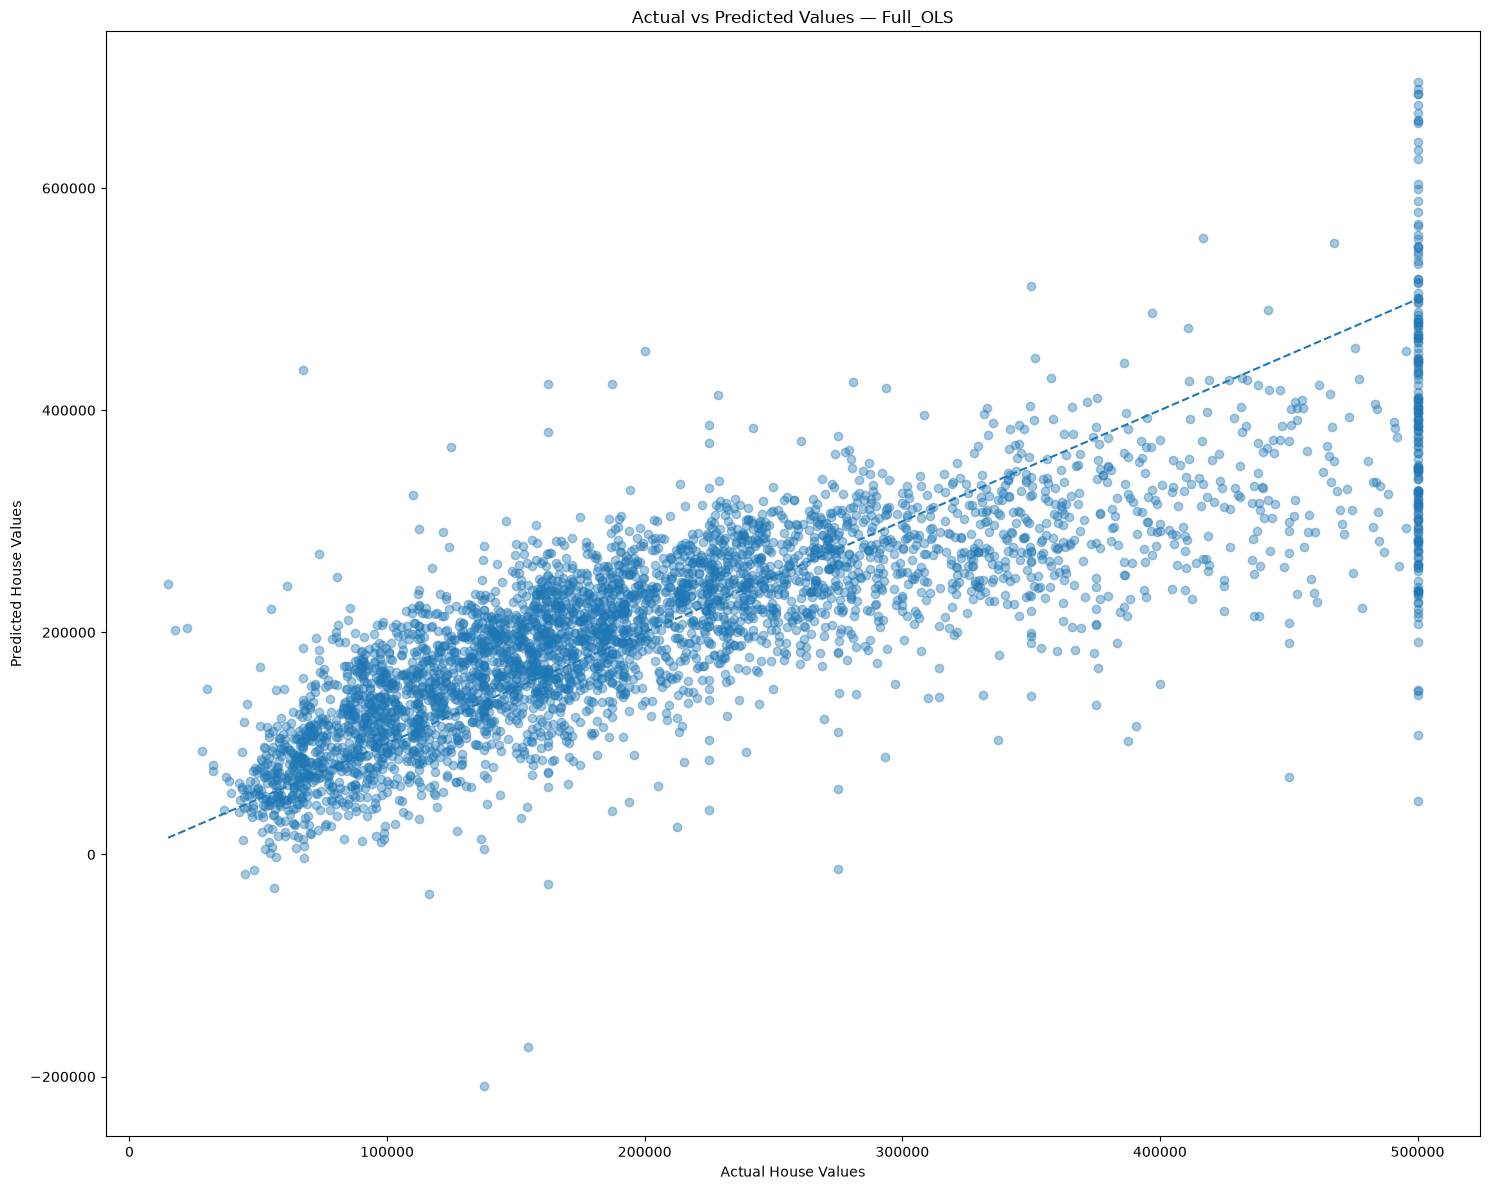

In [69]:
plt.figure(figsize=(15,12))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.4
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title(f"Actual vs Predicted Values — {best_model_name}")

plt.tight_layout()
plt.show()

INTERPRETATION

The plot shows that OLS captures the overall positive relationship between actual and predicted house values: predictions generally rise as actual values rise. However, many points are spread away from the dashed perfect-prediction line, so the model's estimates are not precise for every observation. Predictions tend to be pulled toward the middle of the value range, with some large under- and overestimates; a few predictions are also negative or above the observed target range. The vertical cluster near $500,000 reflects the dataset's cap on recorded house values, which limits the model's ability to distinguish higher-value observations. Overall, the graph indicates useful predictive signal but meaningful residual error, consistent with the test-set results.

### Residual distribution

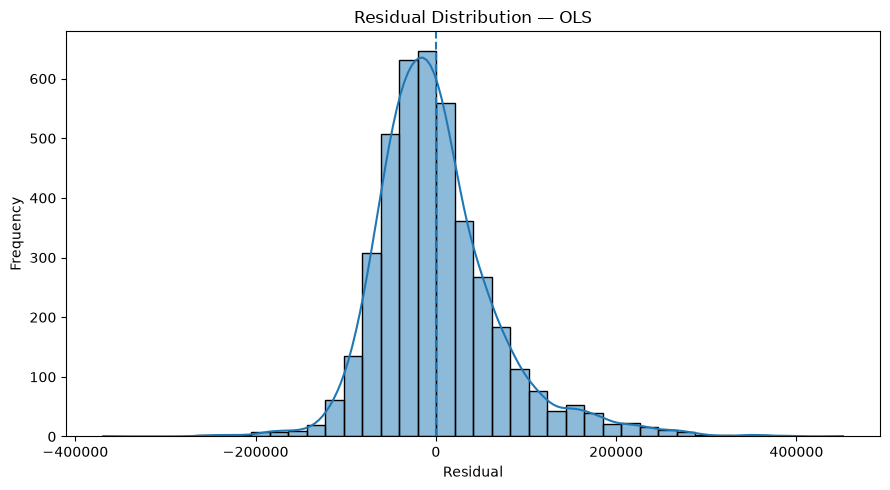

In [ ]:
residuals = y_test - best_predictions

plt.figure(figsize=(9, 5))

sns.histplot(
    residuals,
    kde=True,
    bins=40
)

plt.axvline(0, linestyle="--")

plt.title(f"Residual Distribution — {best_model_name}")
plt.xlabel("Residual")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

INTERPRETATION

Residuals are calculated as actual value minus predicted value. The dashed vertical line marks zero error: residuals to the right are positive, meaning the model underpredicted; residuals to the left are negative, meaning it overpredicted. In this plot, most residuals cluster near zero, so many predictions are relatively close, but the distribution has long tails and a longer positive tail, indicating some large errors and a tendency toward larger underpredictions for a subset of observations. The residuals are not perfectly symmetric or tightly concentrated, so the model's errors are not uniform across all cases. This histogram shows the overall error distribution; a residuals-versus-predicted plot would be needed to assess patterns such as changing error variance or other systematic structure.


## Overall conclusion

This notebook prepared the California housing data for regression, engineered household-level ratios and an income-by-rooms interaction, and built preprocessing pipelines for numeric and categorical features. A mean-prediction baseline, OLS, Ridge, and Lasso were evaluated. Ridge and Lasso regularization strengths were selected with five-fold cross-validation on the training data; all models were then compared using the held-out test set. The notebook also visualized metric comparisons, actual versus predicted values, and the residual distribution, and inspected the fitted Lasso coefficients.

### Model performance

OLS had the lowest test errors, with an RMSE of **$68,917** and an MAE of **$49,710**; its R² was **0.6375**. Lasso and Ridge performed almost identically: their RMSE values were about **$68,922** and **$68,926**, their MAEs about **$49,712** and **$49,716**, and their R² values also rounded to **0.6375**. The baseline was substantially weaker, with an RMSE of **$114,486**, an MAE of **$90,607**, and an R² of **-0.0002**. Thus, the three regression models improve considerably over predicting the mean, but their small score differences do not establish a meaningful predictive winner. OLS is the numerical winner on this split, not necessarily a reliably superior model.

The RMSE and R² comparison plots reflect this pattern: OLS, Ridge, and Lasso are close together and all are well ahead of the baseline. In the actual-versus-predicted plot, predictions generally increase with actual values, but their spread around the perfect-prediction line shows sizable errors. Predictions are pulled toward the middle for many observations, with some large misses; the vertical grouping around the dataset's approximately $500,000 target ceiling also limits interpretation at the high end. The residual histogram is concentrated near zero but has long tails, including a longer positive tail. Since residuals are actual minus predicted, positive residuals indicate underprediction; some observations are therefore substantially underpredicted. The histogram summarizes error sizes but does not by itself test whether error variance changes with fitted value.

Lasso reduced **1 of 17 coefficients** to zero in the reported fit, so it performed little feature removal in this configuration. Its predictive metrics are essentially the same as OLS and Ridge. Coefficients describe model associations in this fitted representation; they should not be interpreted as causal effects, particularly given the multicollinearity identified among several predictors.

### Recommendations

- Treat OLS as the current lowest-RMSE choice, but regard it as effectively tied with Ridge and Lasso on this test split. Ridge is a reasonable alternative when coefficient stability under multicollinearity is a priority; the results do not show that Lasso meaningfully improves prediction or simplifies the feature set here.
- Avoid using this test set repeatedly to choose among models. Compare candidate models using a consistent cross-validation strategy on training data, then reserve the test set for a final evaluation after model selection.
- Inspect residuals against predicted values and key features, especially for high-value areas, to locate systematic errors and changing error spread. The target's upper-value cap means the model cannot learn distinctions above the recorded ceiling; account for this limitation in conclusions and intended use.
- Consider testing nonlinear models or additional feature treatments if improved accuracy is needed, and compare them using the same validation process. Keep the baseline in future comparisons to verify that added complexity provides a real gain.